提交一份含代码与运行结果的 notebook 或分析报告，按任务编号组织，并附本讲退出卡与三道作业。记录软件版本、随机种子、输入特征、标准化方式和拟合范围。评价重点为：数据理解正确、对照可复现、用实际证据解释、承认结论边界；不以图是否“漂亮”或类别是否完全分开评分。


- **Python 版本：**Python `3.13.15`
- **主要软件包版本：**NumPy `2.3.5`；Pandas `2.3.3`；SciPy `1.17.1`；scikit-learn `1.8.0`；umap-learn `0.5.12`；Matplotlib `3.10.8`；threadpoolctl `3.6.0`；Jupyter `1.1.1`；nbformat `5.11.1`。
- **随机种子：**
  - UMAP 基线：`random_state=42`
  - UMAP 种子对照：`random_state=7`
  - 三折交叉验证：`StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`
  - PCA：使用 `svd_solver='full'`，本次没有设置随机种子，因为完整 SVD 的 PCA 是确定性的。
- **输入特征：**`leukemia.csv` 中全部 `7,129` 个探针表达特征；排除 `sample_id`、`original_split`、`diagnosis` 三个元数据列。一个探针列不一定对应一个独立基因，其中可能包括控制探针。
- **标准化方式：**使用 `StandardScaler` 按列做 z-score 标准化，即每个探针在拟合数据范围内被转换为均值约为 `0`、总体标准差约为 `1`（`ddof=0`）。本次检查中，列均值与 0 的最大绝对偏差为 `5.98 × 10^-16`，列标准差与 1 的最大绝对偏差为 `3.33 × 10^-16`。
- **PCA 拟合范围：**描述性 PCA 使用全部 `72` 个样本、全部 `7,129` 个探针，在标准化后的矩阵上拟合；`diagnosis` 没有参与 PCA 拟合，只在拟合完成后用于图上的颜色标记。
- **UMAP 拟合范围：**描述性 UMAP 同样使用全部 `72` 个样本、全部 `7,129` 个标准化探针拟合；诊断标签只用于拟合后的着色。基线参数为：`n_components=2`、`n_neighbors=15`、`min_dist=0.1`、`metric='euclidean'`、`random_state=42`、`n_jobs=1`。对照中分别只改为 `n_neighbors=5`、`min_dist=0.5` 或 `random_state=7`。
- **交叉验证拟合范围：**只使用原始训练部分的 `38` 个样本，其中 ALL `27` 个、AML `11` 个。每一折中，`StandardScaler`、可选的 `PCA(n_components=10, svd_solver='full')` 和 `1-NN` 分类器均只在该折训练数据上拟合，并只转换、预测该折验证数据；未使用另外 `34` 个原始测试样本的标签来调参或评分。

任务一
可选验证仅使用原始 38 个训练样本（27 个 ALL、11 个 AML），不使用另外 34 个测试样本调参或评分；交叉验证为 `StratifiedKFold(3, shuffle=True, random_state=42)`，全部拟合步骤放进 `Pipeline`，评分为 balanced accuracy。

| Pipeline                                                  | 第 1 折 | 第 2 折 | 第 3 折 |  均值 |
| --------------------------------------------------------- | ------: | ------: | ------: | ----: |
| `StandardScaler → 1近邻`                               |   0.819 |   0.875 |   0.833 | 0.843 |
| `StandardScaler → PCA(10, svd_solver='full') → 1近邻` |   0.694 |   0.764 |   0.833 | 0.764 |





任务二

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from umap import UMAP
df = pd.read_csv('git-practice-classroom-latest/assignments/hw04/resources/data/leukemia/leukemia.csv')
X = df.drop(columns=['sample_id', 'original_split', 'diagnosis'])
assert X.shape == (72, 7129) and np.isfinite(X.to_numpy()).all()
Z = StandardScaler().fit_transform(X)  # 此处只描述全部72个样本
print('标准化检查：', np.abs(Z.mean(axis=0)).max(),
      np.abs(Z.std(axis=0, ddof=0)-1).max())
pca = PCA(svd_solver='full').fit(Z)
scores = pca.transform(Z)
evr = pca.explained_variance_ratio_
print('PC1、PC2解释率及合计：', evr[:2], evr[:2].sum())
weights = pd.Series(pca.components_[0], index=X.columns)
print(weights.loc[weights.abs().nlargest(5).index])





标准化检查： 5.982868521591122e-16 3.3306690738754696e-16
PC1、PC2解释率及合计： [0.14921586 0.09446173] 0.2436775909974502
X92518_s_at    0.028786
X95190_at     -0.028177
X98253_at      0.027927
X82895_at      0.027871
Y09616_at      0.027757
dtype: float64


任务三

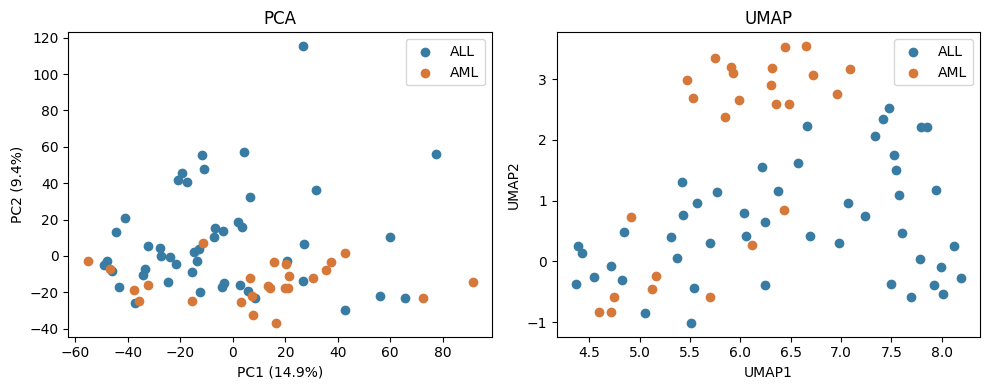

In [10]:
embedding = UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                 metric='euclidean', random_state=42, n_jobs=1).fit_transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for label, color in [('ALL', '#387ca3'), ('AML', '#d57839')]:
    mask = df.diagnosis.eq(label).to_numpy()
    axes[0].scatter(scores[mask, 0], scores[mask, 1], label=label, c=color)
    axes[1].scatter(embedding[mask, 0], embedding[mask, 1], label=label, c=color)
axes[0].set(xlabel=f'PC1 ({evr[0]:.1%})', ylabel=f'PC2 ({evr[1]:.1%})', title='PCA')
axes[1].set(xlabel='UMAP1', ylabel='UMAP2', title='UMAP')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

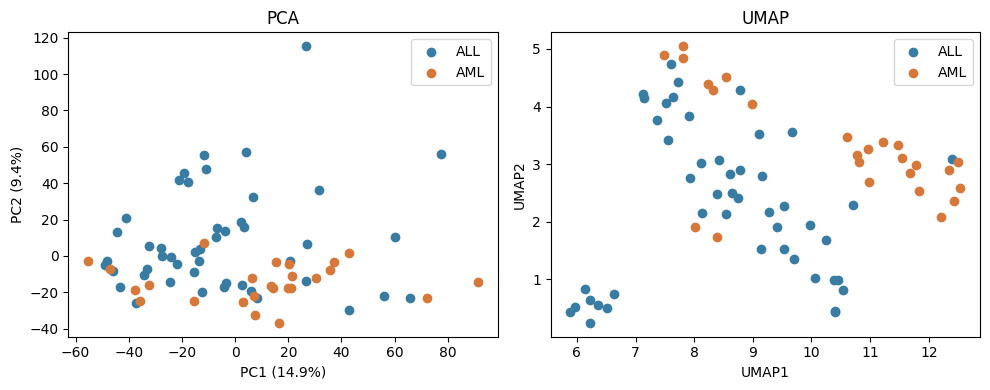

In [11]:
embedding = UMAP(n_components=2, n_neighbors=5, min_dist=0.1,
                 metric='euclidean', random_state=42, n_jobs=1).fit_transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for label, color in [('ALL', '#387ca3'), ('AML', '#d57839')]:
    mask = df.diagnosis.eq(label).to_numpy()
    axes[0].scatter(scores[mask, 0], scores[mask, 1], label=label, c=color)
    axes[1].scatter(embedding[mask, 0], embedding[mask, 1], label=label, c=color)
axes[0].set(xlabel=f'PC1 ({evr[0]:.1%})', ylabel=f'PC2 ({evr[1]:.1%})', title='PCA')
axes[1].set(xlabel='UMAP1', ylabel='UMAP2', title='UMAP')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

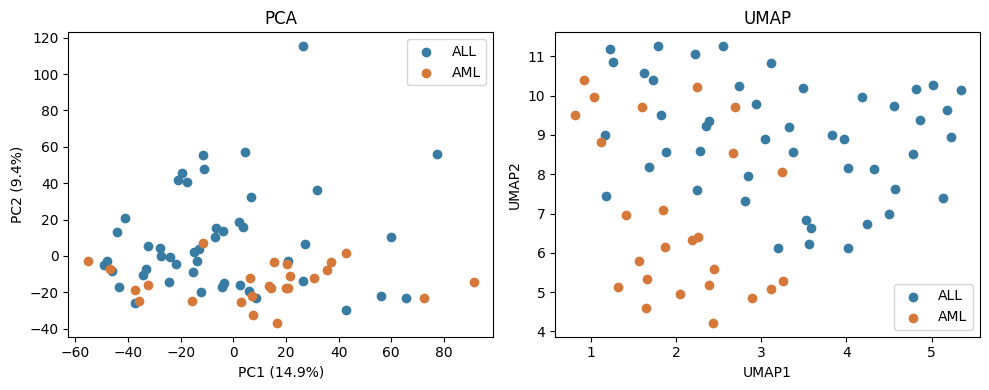

In [12]:
embedding = UMAP(n_components=2, n_neighbors=15, min_dist=0.5,
                 metric='euclidean', random_state=42, n_jobs=1).fit_transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for label, color in [('ALL', '#387ca3'), ('AML', '#d57839')]:
    mask = df.diagnosis.eq(label).to_numpy()
    axes[0].scatter(scores[mask, 0], scores[mask, 1], label=label, c=color)
    axes[1].scatter(embedding[mask, 0], embedding[mask, 1], label=label, c=color)
axes[0].set(xlabel=f'PC1 ({evr[0]:.1%})', ylabel=f'PC2 ({evr[1]:.1%})', title='PCA')
axes[1].set(xlabel='UMAP1', ylabel='UMAP2', title='UMAP')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

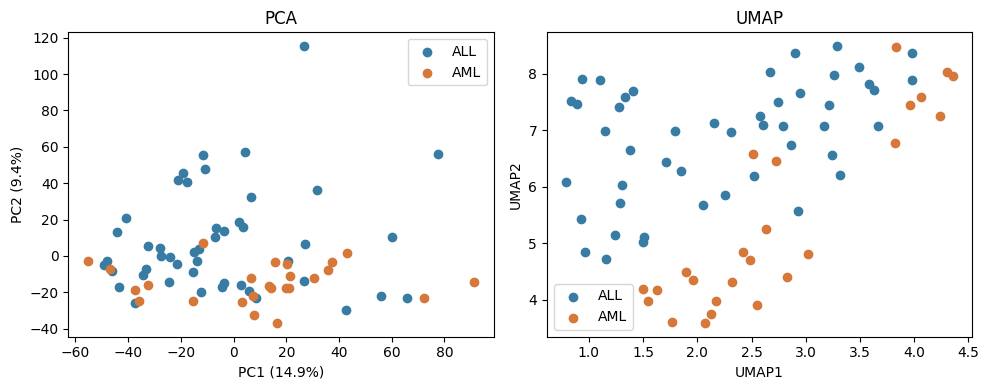

In [13]:
embedding = UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                 metric='euclidean', random_state=7, n_jobs=1).fit_transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for label, color in [('ALL', '#387ca3'), ('AML', '#d57839')]:
    mask = df.diagnosis.eq(label).to_numpy()
    axes[0].scatter(scores[mask, 0], scores[mask, 1], label=label, c=color)
    axes[1].scatter(embedding[mask, 0], embedding[mask, 1], label=label, c=color)
axes[0].set(xlabel=f'PC1 ({evr[0]:.1%})', ylabel=f'PC2 ({evr[1]:.1%})', title='PCA')
axes[1].set(xlabel='UMAP1', ylabel='UMAP2', title='UMAP')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

退出卡：用“主张—证据—推理—边界”四句话回答驱动问题，引用一项 PCA 结果与一项 UMAP 对照，并提出下一步验证。

课后用自己的话解释：

PCA 第一主成分代表什么？结合本次解释率与一个探针权重回答。
为什么 PCA 前通常需要标准化？结合原尺度对照，说明作用与代价。
UMAP 图能说明什么，不能说明什么？结合一次参数或种子对照回答。
评价关注拟合范围、可复现对照和解释边界，不以图是否漂亮或分组是否清楚评分。请以自己实际运行得到的结果为准，不要只抄写示例结论。

退出卡


主张：**我不同意“二维图分得开，就证明发现了疾病机制，并可以预测新患者”这句话。当前 PCA 和 UMAP 图说明 ALL、AML 样本的表达数据中可能存在值得进一步研究的结构，但图本身既不是疾病机制证据，也不是新患者预测性能的证据。

**证据：**标准化 PCA 中，PC1 解释约 `14.9%`的总体方差，PC2 解释约 `9.4%`，两者合计仅约 `24.37%`；PC1 的高权重探针之一是 `X92518_s_at`，权重为 `+0.028786`。UMAP 的图形也会随参数改变：基线设置 `n_neighbors=15, min_dist=0.1, random_state=42`时，AML 大多在上方但仍有与 ALL 接近或混合的样本；改成 `n_neighbors=5`或只把随机种子改为 `7`后，图上的岛屿形状、相对距离和类别分离程度明显变化；只把 `min_dist`改为 `0.5`后，两类在图中的混合更明显。

**推理：**PC1 是使所有样本投影后总体方差最大的方向，不是专门为了把 ALL 和 AML 分开的方向，也不等于某一个探针或基因。UMAP 也没有使用诊断标签来拟合，它把高维样本的局部邻近关系压缩到二维；图上相近的点可以作为“这些样本在原始表达模式上可能较相似”的探索线索，但二维坐标轴、岛屿之间的距离、岛屿面积和图形方向没有直接的生物学含义。既然只改一个 UMAP 参数或随机种子，图形和表面上的分离程度就会改变，就不能只挑一张分得最开的图得出强结论。

**边界：**这些结果能支持“ALL 和 AML 在这 72 个样本的表达数据中可能存在某些可探索的结构差异”，但不能证明某个高权重探针是致病机制，不能证明真实亚型数量，也不能说明对新患者一定有预测能力。本数据没有批次字段，不能宣称已排除批次效应。若要证明预测能力，应在不泄露信息的训练流程中拟合标准化、PCA 和分类器，并用独立的、未参与调参的新患者队列评价；若要把图形模式升级为疾病机制结论，还需要在独立队列重复，并结合相关通路分析和功能实验验证。

**作业：**用自己的话分别解释：

1. PCA 第一主成分代表什么？结合本次解释率和一个探针权重说明。
2. 为什么 PCA 前通常需要考虑标准化？结合原尺度对照说明它的作用与代价。
3. UMAP 图能说明什么，不能说明什么？结合一次参数或种子对照说明。

**1.PCA 第一主成分代表什么？**
PC1 可以理解为：在 7,129 个探针构成的高维空间中，找出一条让 72 个样本“拉得最开”的方向。它最大化的是样本投影到该方向后的总体方差，而不是最大化 ALL 和 AML 的分类差异。

本次分析中，PC1 解释约 14.9% 的总体方差，说明它是所有变化中最强的一部分，但绝大多数变化仍不在 PC1 中。X92518_s_at 在 PC1 上的权重为 +0.028786，表示该探针的标准化表达值较高时，通常会把样本的 PC1 得分往正方向推；但 PC1 是全部探针按权重共同组成的方向，不是 X92518_s_at 这个单独探针，更不能直接把它称为致病基因。

PC1 的正负号可以整体翻转。例如，全部权重和全部 PC1 得分同时乘以 -1，图左右会对调，但样本间的相对关系、解释率和结论都不变。
**2. 为什么 PCA 前通常需要考虑标准化？**
PCA 根据“变化有多大”寻找方向。如果某些探针原始数值范围很大、方差很大，即使它们对研究问题不重要，也可能主导 PCA。按列使用 StandardScaler 后，每个探针的均值约为 0、标准差约为 1，PCA 就不会天然偏向数值量级大的探针。

本次标准化检查中，变换后列均值与 0 的最大偏差约为 5.98 × 10^-16，标准差与 1 的最大偏差约为 3.33 × 10^-16，可视为标准化成功。

与仅中心化、未标准化的原尺度 PCA 相比，原尺度 PCA 会更容易被大尺度或高方差探针支配，因此其解释率和高权重探针可能明显不同。标准化的好处是让各探针在 PCA 中有更公平的起点；代价是它也可能把原来变化很小、主要由测量噪声组成的探针放大到与高变异探针同等尺度。因此，标准化不是自动等于“更真实”，而是针对“希望各特征先同尺度参与 PCA”的分析选择。

另外，这里的 StandardScaler 是 PCA 前的统计处理，不等于微阵列实验流程中的上游归一化；由于数据中有负值，本课不直接取对数。
**3. UMAP 图能说明什么，不能说明什么？**
UMAP 图能说明：在当前标准化、距离度量和参数设置下，原始高维表达模式中一些局部相近的样本，被投影到二维后仍然呈现出一定结构。四张图都显示 ALL 和 AML 并非完全随机混在一起，说明诊断可能和表达结构存在关联，值得继续调查。

但 UMAP 图不能单独说明：

- 不能证明已经发现疾病机制；
- 不能证明图中的每个岛屿都是真实疾病亚型；
- 不能把岛屿之间的二维距离解释成精确的生物学距离；
- 不能把横轴 UMAP1、纵轴 UMAP2 当作有固定生物学含义的指标；
- 不能仅凭图上类别分开，证明能够预测没见过的新患者；
- 不能因为没有批次字段就宣称已经排除了批次影响。
  参数对照正好说明了这一点。基线图中 AML 大多位于上方，但仍与部分 ALL 接近；改为 n_neighbors=5 时，UMAP 更强调局部邻居关系，图形被拉成不同的局部区域；改为 min_dist=0.5 时，点之间被要求保留更大间隔，类别混合更明显；只把随机种子从 42 改为 7，整体布局和分离的视觉效果也改变。这说明相对稳定的可能是某些局部邻近关系，而岛屿数量、方向、面积、间距及“看起来分得有多开”并不稳定，不能被过度解释。